## Python - Tratamento e Análise exploratória

In [494]:
# importando as bibliotecas necessárias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as srn

In [495]:
# importando o dataset
df = pd.read_csv('Campe_Supply_Corrompido.csv')
df.head(10)

,UNNAMED: 0,data da venda,SETOR,PRODUTO,VENDEDOR,região,ESTADO,cliente,FATURAMENTO,margem de lucro,LUCRO,coluna_inutil_0,coluna_inutil_1
0,NaN,2035-01-01 00:00:00,Carnes,kuína,Amaral,Sudeste,Minas Gerais,Atacado,"633,45","0,13","82,3485",PvlTk,SvWK1
1,NaN,2035-01-01 00:00:00,Latícinio,Queijo,Leo,Sudeste,Minas Gerais,Atacarejo,"611,4","0,07","42,798",4ZBrt,gwduN
2,NaN,2035-01-01 00:00:00,Congelados,Sorvete,Leo,Nordeste,NaN,Atacarejo,"721,52","0,08",NaN,Mc6m1,NFY0g
3,NaN,2035-01-01 00:00:00,Carnes,Bovina,Daniele,Sudeste,São Paulo,Atacado,"679,39",0.09,"61,1451",ROb74,QDXmd
4,NaN,2035-01-01 00:00:00,Carnes,Frango,Vanessa,Sul,Rio Grande do Sul,tarejo,964.52,"0,19","183,2588",n8NR2,Ml1t1
5,NaN,2035-01-01 00:00:00,Latícinio,Coalhada,Leo,Nordeste,Rio Grande do Norte,Attcarejo,"565,7","0,08","45,256",9ZNcS,skEvZ
6,NaN,2035-01-01 00:00:00,Cvrnes,Frango,Vanessa,Nordeste,Rio Grande do Norte,Atacarejo,"721,01",0.05,"36,0505",IDzv5,IXSeY
7,NaN,2035-01-01 00:00:00,Carnes,Bovina,Vanessa,Sul,Rio Grande do Sul,Atacado,"649,4",0.11,"71,434",gineL,YohO9
8,NaN,2035-01-02 00:00:00,Latícinio,Coalhada,NaN,Sudeste,Minas Gerais,Atacarejo,"789,01","0,19",149.9119,Xbzks,LDKbJ
9,NaN,NaN,Latícinio,Queijo,Daniele,Nordeste,Bahia,Atacado,"574,3","0,05","28,715",wa9bD,prMxB


### Iniciando Análise Exploratória

In [496]:
# Padronizando os nomes das colunas
df.columns = ["Sem nome", "Data da Venda", "Setor", "Produto", "Vendedor", "Região", "Estado", "Cliente", "Faturamento", "Margem de Lucro", "Lucro", "Inutil1", "Inutil2"]

In [497]:
df.head(10)

,Sem nome,Data da Venda,Setor,Produto,Vendedor,Região,Estado,Cliente,Faturamento,Margem de Lucro,Lucro,Inutil1,Inutil2
0,NaN,2035-01-01 00:00:00,Carnes,kuína,Amaral,Sudeste,Minas Gerais,Atacado,"633,45","0,13","82,3485",PvlTk,SvWK1
1,NaN,2035-01-01 00:00:00,Latícinio,Queijo,Leo,Sudeste,Minas Gerais,Atacarejo,"611,4","0,07","42,798",4ZBrt,gwduN
2,NaN,2035-01-01 00:00:00,Congelados,Sorvete,Leo,Nordeste,NaN,Atacarejo,"721,52","0,08",NaN,Mc6m1,NFY0g
3,NaN,2035-01-01 00:00:00,Carnes,Bovina,Daniele,Sudeste,São Paulo,Atacado,"679,39",0.09,"61,1451",ROb74,QDXmd
4,NaN,2035-01-01 00:00:00,Carnes,Frango,Vanessa,Sul,Rio Grande do Sul,tarejo,964.52,"0,19","183,2588",n8NR2,Ml1t1
5,NaN,2035-01-01 00:00:00,Latícinio,Coalhada,Leo,Nordeste,Rio Grande do Norte,Attcarejo,"565,7","0,08","45,256",9ZNcS,skEvZ
6,NaN,2035-01-01 00:00:00,Cvrnes,Frango,Vanessa,Nordeste,Rio Grande do Norte,Atacarejo,"721,01",0.05,"36,0505",IDzv5,IXSeY
7,NaN,2035-01-01 00:00:00,Carnes,Bovina,Vanessa,Sul,Rio Grande do Sul,Atacado,"649,4",0.11,"71,434",gineL,YohO9
8,NaN,2035-01-02 00:00:00,Latícinio,Coalhada,NaN,Sudeste,Minas Gerais,Atacarejo,"789,01","0,19",149.9119,Xbzks,LDKbJ
9,NaN,NaN,Latícinio,Queijo,Daniele,Nordeste,Bahia,Atacado,"574,3","0,05","28,715",wa9bD,prMxB


In [498]:
#Verificando o tamanho do dataset
df.shape

(1690, 13)

In [499]:
#Verificando tipos de dados e contagem de não-nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1690 entries, 0 to 1689
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Sem nome         31 non-null     object
 1   Data da Venda    1606 non-null   object
 2   Setor            1604 non-null   object
 3   Produto          1607 non-null   object
 4   Vendedor         1608 non-null   object
 5   Região           1606 non-null   object
 6   Estado           1605 non-null   object
 7   Cliente          1603 non-null   object
 8   Faturamento      1602 non-null   object
 9   Margem de Lucro  1610 non-null   object
 10  Lucro            1602 non-null   object
 11  Inutil1          1690 non-null   object
 12  Inutil2          1690 non-null   object
dtypes: object(13)
memory usage: 171.8+ KB


O dataset possui colunas inúteis que deverão ser excluídas, como "Sem nome", "Inutil1" e "Inutil2". <p>
Também possui valores nulos em quase todas as colunas, exceto nas colunas inúteis que serão excluídas. <p>
Todas as colunas estão com objeto até as colunas que deveriam ser numéricas como por exemplo faturamento.

#### Inspecionando a coluna Data da Venda

In [500]:
#Verificando quantos valores nulos existem na coluna "Data da Venda"

df["Data da Venda"].isnull().sum()

84

A coluna Data da Venda possui 84 valores nulos que serão tratados

#### Inspecionando a coluna Setor

In [501]:
#Verificando quantos valores nulos existem na coluna "Setor"

df["Setor"].isnull().sum()

86

In [502]:
# Verificando quais categorias existem na coluna "Setor"

df["Setor"].value_counts(dropna=False)

Setor
Congelados    374
Latícinio     373
Bebidas       361
Carnes        346
NaN            86
             ... 
Latíconio       1
Lattcinio       1
Carves          1
Cobgelados      1
earnes          1
Name: count, Length: 140, dtype: int64

A coluna Setor possui 86 valores nulos e 140 variantes de valores onde alguns estão com erro de digitação como por exemplo Carves e earnes

#### Inspecionando a coluna Produto

In [503]:
# Verificando quantos valores nulos existem na coluna "Produto"

df["Produto"].isnull().sum()

83

In [504]:
# Verificando quais categorias existem na coluna "Produto"

df["Produto"].value_counts(dropna=False)

Produto
Queijo           222
Sorvete          216
Frango           155
Refrigerantes    154
Cervejas         152
                ... 
Sulos              1
Pizta              1
Lhite              1
Sprvete            1
Clalhada           1
Name: count, Length: 153, dtype: int64

A coluna Produto possui 83 valores nulos e 153 variantes de valores onde alguns estão com erro de digitação como por exemplo Sprvete e Lhite

#### Inspecionando a coluna Vendedor

In [505]:
# Verificando quantos valores nulos existem na coluna "Vendedor"

df["Vendedor"].isnull().sum()

82

In [506]:
# Verificando quantos valores diferentes existem na coluna "Vendedor"

df["Vendedor"].value_counts(dropna=False)

Vendedor
Vanessa    443
Amaral     317
Leo        235
Daniele    218
Jonas      116
          ... 
Jotas        1
Vanissa      1
mvandro      1
Dbniele      1
Evtndro      1
Name: count, Length: 153, dtype: int64

A coluna Vendedor possui 82 valores nulos e 153 variantes de valores onde alguns estão com erro de digitação como por exemplo Dbniele e Evtndro

In [507]:
df.head()

,Sem nome,Data da Venda,Setor,Produto,Vendedor,Região,Estado,Cliente,Faturamento,Margem de Lucro,Lucro,Inutil1,Inutil2
0,NaN,2035-01-01 00:00:00,Carnes,kuína,Amaral,Sudeste,Minas Gerais,Atacado,"633,45","0,13","82,3485",PvlTk,SvWK1
1,NaN,2035-01-01 00:00:00,Latícinio,Queijo,Leo,Sudeste,Minas Gerais,Atacarejo,"611,4","0,07","42,798",4ZBrt,gwduN
2,NaN,2035-01-01 00:00:00,Congelados,Sorvete,Leo,Nordeste,NaN,Atacarejo,"721,52","0,08",NaN,Mc6m1,NFY0g
3,NaN,2035-01-01 00:00:00,Carnes,Bovina,Daniele,Sudeste,São Paulo,Atacado,"679,39",0.09,"61,1451",ROb74,QDXmd
4,NaN,2035-01-01 00:00:00,Carnes,Frango,Vanessa,Sul,Rio Grande do Sul,tarejo,964.52,"0,19","183,2588",n8NR2,Ml1t1


#### inspecionando a coluna Região

In [508]:
# Verificando quantos valores nulos existem na coluna "Região"

df["Região"].isnull().sum()

84

In [509]:
# Verificando quantos valores diferentes existem na coluna "Região"

df["Região"].value_counts(dropna=False)

Região
Sudeste     506
Nordeste    478
Sul         463
NaN          84
mul           4
           ... 
Spl           1
Suduste       1
Nordiste      1
Suveste       1
lul           1
Name: count, Length: 128, dtype: int64

A coluna Região possui 84 valores nulos e 128 variantes de valores onde alguns estão com erro de digitação como por exemplo Spl e lul

#### inspecionando a coluna Estado

In [510]:
# Verificando quantos valores nulos existem na coluna "Estado"

df["Estado"].isnull().sum()

85

In [511]:
# Verificando quantos valores diferentes existem na coluna "Estado"

df["Estado"].value_counts(dropna=False)

Estado
Rio de Janeiro         171
Minas Gerais           170
Bahia                  166
São Paulo              164
Rio Grande do Norte    164
                      ... 
RiobGrande do Norte      1
Minas ferais             1
Riovde Janeiro           1
Rio Grande dk Sul        1
Rio de Janepro           1
Name: count, Length: 161, dtype: int64

A coluna Estado possui 85 valores nulos e 161 variantes de valores onde alguns estão com erro de digitação como por exemplo RiobGrande do Norte e Rio Grande dk Sul

#### inspecionando a coluna Cliente


In [512]:
# Verificando quantos valores nulos existem na coluna "Cliente"

df["Cliente"].isnull().sum()

87

In [513]:
# Verificando quantos valores diferentes existem na coluna "Cliente"

df["Cliente"].value_counts(dropna=False)

Cliente
Atacarejo    482
Varejo       475
Atacado      471
NaN           87
Atacedo        3
            ... 
Atagarejo      1
zarejo         1
Atjcarejo      1
Axacarejo      1
Varevo         1
Name: count, Length: 150, dtype: int64

A coluna Cliente possui 87 valores nulos e 150 variantes de valores onde alguns estão com erro de digitação como por exemplo Atacarejo e Atjcarejo 

In [514]:
df.head()

,Sem nome,Data da Venda,Setor,Produto,Vendedor,Região,Estado,Cliente,Faturamento,Margem de Lucro,Lucro,Inutil1,Inutil2
0,NaN,2035-01-01 00:00:00,Carnes,kuína,Amaral,Sudeste,Minas Gerais,Atacado,"633,45","0,13","82,3485",PvlTk,SvWK1
1,NaN,2035-01-01 00:00:00,Latícinio,Queijo,Leo,Sudeste,Minas Gerais,Atacarejo,"611,4","0,07","42,798",4ZBrt,gwduN
2,NaN,2035-01-01 00:00:00,Congelados,Sorvete,Leo,Nordeste,NaN,Atacarejo,"721,52","0,08",NaN,Mc6m1,NFY0g
3,NaN,2035-01-01 00:00:00,Carnes,Bovina,Daniele,Sudeste,São Paulo,Atacado,"679,39",0.09,"61,1451",ROb74,QDXmd
4,NaN,2035-01-01 00:00:00,Carnes,Frango,Vanessa,Sul,Rio Grande do Sul,tarejo,964.52,"0,19","183,2588",n8NR2,Ml1t1


#### Inspecionando a coluna Faturamento

In [515]:
df['Faturamento'].describe()

count      1602
unique     1451
top       927,1
freq          3
Name: Faturamento, dtype: object

In [516]:
# Os valores não estão como numéricos, então vou converte-los para conseguir fazer a análise deles.

df['Faturamento'] = pd.to_numeric(df['Faturamento'].str.replace(',', '.'), errors='coerce')
df['Faturamento'].describe()

count    1569.000000
mean      896.626673
std       400.539175
min       520.360000
25%       670.190000
50%       799.530000
75%       948.200000
max      8581.600000
Name: Faturamento, dtype: float64

In [517]:
# Verificando quantos valores nulos existem na coluna "Faturamento"

df['Faturamento'].isnull().sum()

121

Text(0.5, 1.0, 'Boxplot do Faturamento')

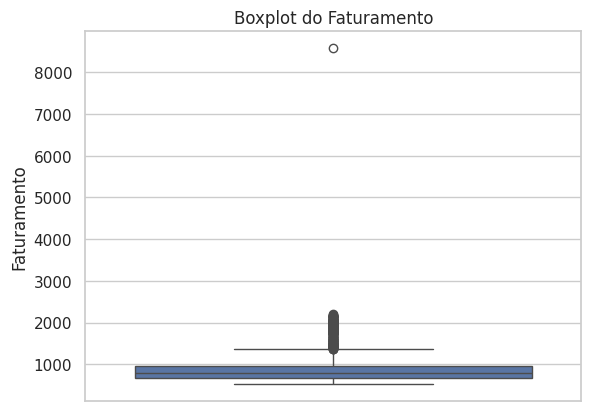

In [518]:
srn.boxplot(df['Faturamento']).set_title('Boxplot do Faturamento')

O uso do bloxplot neste caso confirmou visualmente um ponto extremo isolado acima da marca de 8.000, bem distante do comportamento padrão da base, é mais uma confirmação de que se trata de um outlier.

#### Inspecionando a coluna Margem de Lucro

In [519]:
df['Margem de Lucro'].describe()

count     1610
unique      61
top       0,08
freq       100
Name: Margem de Lucro, dtype: object

In [520]:
# Alterando o tipo de dado da coluna "Margem de Lucro" para numérico

df['Margem de Lucro'] = pd.to_numeric(df['Margem de Lucro'].str.replace(',', '.'), errors='coerce')
df['Margem de Lucro'].describe()

count    1581.000000
mean        0.119311
std         0.043098
min         0.000000
25%         0.080000
50%         0.120000
75%         0.160000
max         0.190000
Name: Margem de Lucro, dtype: float64

In [521]:
# Verificando quantos valores nulos existem na coluna "Margem de Lucro"
df['Margem de Lucro'].isnull().sum()

109

Text(0.5, 1.0, 'Boxplot da Margem de Lucro')

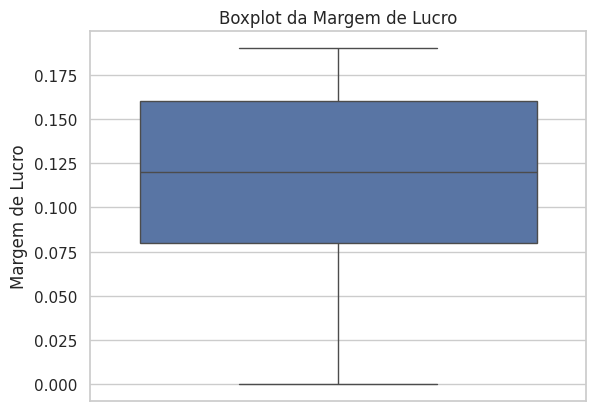

In [522]:
srn.boxplot(df['Margem de Lucro']).set_title('Boxplot da Margem de Lucro')

O uso do bloxplot neste caso confirma visualmente que a coluna Margem de Lucro não apresenta outlier e que os dados variam de uma forma controlada entre 0.0 até próximo de 0.175

#### Inspecionando a coluna Lucro

In [523]:
df['Lucro'].describe()

count       1602
unique      1461
top       45,494
freq           3
Name: Lucro, dtype: object

In [524]:
# Convertendo a coluna "Lucro" para numérico

df['Lucro'] = pd.to_numeric(df['Lucro'].str.replace(',', '.'), errors='coerce')
df['Lucro'].describe()

count    1.570000e+03
mean     3.474494e+03
std      9.686204e+04
min      2.669350e+01
25%      6.545850e+01
50%      9.524290e+01
75%      1.306109e+02
max      3.260000e+06
Name: Lucro, dtype: float64

In [525]:
# Verificando quantos valores nulos existem na coluna "Margem de Lucro"
df['Margem de Lucro'].isnull().sum()

109

Text(0.5, 1.0, 'Boxplot do Lucro')

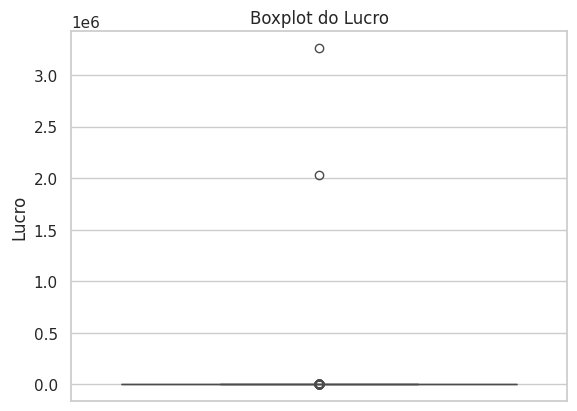

In [526]:
srn.boxplot(df['Lucro']).set_title('Boxplot do Lucro')

Este boxplot evidencia ainda mais a discrepancia do outlier que ultrapassa 3 milhões, o que acaba até distorcendo a visualização dos demais valores.

In [527]:
df.head(10)

,Sem nome,Data da Venda,Setor,Produto,Vendedor,Região,Estado,Cliente,Faturamento,Margem de Lucro,Lucro,Inutil1,Inutil2
0,NaN,2035-01-01 00:00:00,Carnes,kuína,Amaral,Sudeste,Minas Gerais,Atacado,633.45,0.13,82.3485,PvlTk,SvWK1
1,NaN,2035-01-01 00:00:00,Latícinio,Queijo,Leo,Sudeste,Minas Gerais,Atacarejo,611.40,0.07,42.7980,4ZBrt,gwduN
2,NaN,2035-01-01 00:00:00,Congelados,Sorvete,Leo,Nordeste,NaN,Atacarejo,721.52,0.08,NaN,Mc6m1,NFY0g
3,NaN,2035-01-01 00:00:00,Carnes,Bovina,Daniele,Sudeste,São Paulo,Atacado,679.39,0.09,61.1451,ROb74,QDXmd
4,NaN,2035-01-01 00:00:00,Carnes,Frango,Vanessa,Sul,Rio Grande do Sul,tarejo,964.52,0.19,183.2588,n8NR2,Ml1t1
5,NaN,2035-01-01 00:00:00,Latícinio,Coalhada,Leo,Nordeste,Rio Grande do Norte,Attcarejo,565.70,0.08,45.2560,9ZNcS,skEvZ
6,NaN,2035-01-01 00:00:00,Cvrnes,Frango,Vanessa,Nordeste,Rio Grande do Norte,Atacarejo,721.01,0.05,36.0505,IDzv5,IXSeY
7,NaN,2035-01-01 00:00:00,Carnes,Bovina,Vanessa,Sul,Rio Grande do Sul,Atacado,649.40,0.11,71.4340,gineL,YohO9
8,NaN,2035-01-02 00:00:00,Latícinio,Coalhada,NaN,Sudeste,Minas Gerais,Atacarejo,789.01,0.19,149.9119,Xbzks,LDKbJ
9,NaN,NaN,Latícinio,Queijo,Daniele,Nordeste,Bahia,Atacado,574.30,0.05,28.7150,wa9bD,prMxB


### Tratamento dos Dados

In [528]:
# 1º

# Removendo colunas irrelevantes
df = df.drop(columns=["Sem nome", "Inutil1", "Inutil2"])

df.head()

,Data da Venda,Setor,Produto,Vendedor,Região,Estado,Cliente,Faturamento,Margem de Lucro,Lucro
0,2035-01-01 00:00:00,Carnes,kuína,Amaral,Sudeste,Minas Gerais,Atacado,633.45,0.13,82.3485
1,2035-01-01 00:00:00,Latícinio,Queijo,Leo,Sudeste,Minas Gerais,Atacarejo,611.40,0.07,42.7980
2,2035-01-01 00:00:00,Congelados,Sorvete,Leo,Nordeste,NaN,Atacarejo,721.52,0.08,NaN
3,2035-01-01 00:00:00,Carnes,Bovina,Daniele,Sudeste,São Paulo,Atacado,679.39,0.09,61.1451
4,2035-01-01 00:00:00,Carnes,Frango,Vanessa,Sul,Rio Grande do Sul,tarejo,964.52,0.19,183.2588


In [529]:
# 2º Tratando a coluna "Data da Venda" para o formato brasileiro

df["Data da Venda"] = pd.to_datetime(df["Data da Venda"], errors='coerce').dt.strftime('%d/%m/%Y')

df.head()

,Data da Venda,Setor,Produto,Vendedor,Região,Estado,Cliente,Faturamento,Margem de Lucro,Lucro
0,01/01/2035,Carnes,kuína,Amaral,Sudeste,Minas Gerais,Atacado,633.45,0.13,82.3485
1,01/01/2035,Latícinio,Queijo,Leo,Sudeste,Minas Gerais,Atacarejo,611.40,0.07,42.7980
2,01/01/2035,Congelados,Sorvete,Leo,Nordeste,NaN,Atacarejo,721.52,0.08,NaN
3,01/01/2035,Carnes,Bovina,Daniele,Sudeste,São Paulo,Atacado,679.39,0.09,61.1451
4,01/01/2035,Carnes,Frango,Vanessa,Sul,Rio Grande do Sul,tarejo,964.52,0.19,183.2588


In [530]:
df['Data da Venda'].isnull().sum()

84

In [531]:
# Preenchendo os valores nulos usando a data anterior e a posterior caso o primeiro seja nulo

df["Data da Venda"] = df["Data da Venda"].ffill().bfill()

In [532]:
df['Data da Venda'].isnull().sum()

0

In [533]:
# 3º Tratando a coluna "Setor"

import difflib

# Substituindo os valores incorretos pelos corretos usando a função get_close_matches do módulo difflib

setores_oficiais = ['Congelados', 'Latícinio', 'Bebidas', 'Carnes']

def corrigir_setor(valor):
    
    if pd.isna(valor):
        return valor
    
    correspondencia = difflib.get_close_matches(str(valor), setores_oficiais, n=1, cutoff=0.6)
    
    if correspondencia:
        return correspondencia[0]
    else:
        return valor

df['Setor'] = df['Setor'].apply(corrigir_setor)

print(df['Setor'].value_counts(dropna=False))

Setor
Latícinio     408
Congelados    402
Bebidas       402
Carnes        392
NaN            86
Name: count, dtype: int64


In [534]:
df['Setor'].isnull().sum()

86

In [535]:
# Substituindo os valores nulos da coluna "Setor" pela moda

moda_setor = df["Setor"].mode()[0]
df["Setor"] = df["Setor"].fillna(moda_setor)

In [536]:
df['Setor'].isnull().sum()

0

In [537]:
# 4º Tratando a coluna "Produto"

produtos_oficiais = ['Sorvete', 'Queijo', 'Cervejas', 'Bovina','Refrigerantes','Frango','Lasanha','Sucos','Suína','Leite','Coalhada','Pizza']

# Substituindo os valores incorretos pelos corretos usando a função get_close_matches do módulo difflib

def corrigir_produto(valor):
    
    if pd.isna(valor): 
        return valor
    
    match = difflib.get_close_matches(str(valor), produtos_oficiais, n=1, cutoff=0.5)
    
    return match[0] if match else valor

df['Produto'] = df['Produto'].apply(corrigir_produto)

# Tratando os valores nulos preenchendo com a moda

df['Produto'] = df['Produto'].fillna(df['Produto'].mode()[0])

print(df['Produto'].value_counts(dropna=False))

Produto
Queijo           319
Sorvete          236
Refrigerantes    172
Frango           169
Cervejas         169
Bovina           153
Leite            139
Lasanha           85
Suína             81
Pizza             79
Sucos             67
Coalhada          21
Name: count, dtype: int64


In [538]:
df['Produto'].isnull().sum()

0

In [539]:
# 5º Tratando a coluna "Vendedor"

vendedores_oficiais = ['Amaral', 'Leo', 'Daniele', 'Vanessa', 'Evandro', 'Jonas']

# Substituindo os valores incorretos pelos corretos usando a função get_close_matches do módulo difflib

def corrigir_vendedor(valor):
    
    if pd.isna(valor):
        return valor
    match = difflib.get_close_matches(str(valor), vendedores_oficiais, n=1, cutoff=0.5)
    
    return match[0] if match else valor

df['Vendedor'] = df['Vendedor'].apply(corrigir_vendedor)

# Preenchendo os valores nulos da coluna "Vendedor" com a moda

df['Vendedor'] = df['Vendedor'].fillna(df['Vendedor'].mode()[0])

print(df['Vendedor'].value_counts(dropna=False))

Vendedor
Vanessa    568
Amaral     356
Leo        259
Daniele    246
Jonas      135
Evandro    126
Name: count, dtype: int64


In [540]:
df['Vendedor'].isnull().sum()

0

In [541]:
# 6º Tratando a coluna "Região"

regioes_oficiais = ['Sudeste', 'Sul', 'Nordeste', 'Centro-Oeste','Norte']

# Substituindo os valores incorretos pelos corretos usando a função get_close_matches do módulo difflib

def corrigir_regiao(valor):
    
    if pd.isna(valor): 
        return valor
    
    match = difflib.get_close_matches(str(valor), regioes_oficiais, n=1, cutoff=0.5)
    
    return match[0] if match else valor

df['Região'] = df['Região'].apply(corrigir_regiao)

# Preenchendo os valores nulos da coluna "Região" com a moda

df['Região'] = df['Região'].fillna(df['Região'].mode()[0])

print(df['Região'].value_counts(dropna=False))

Região
Sudeste     642
Nordeste    537
Sul         511
Name: count, dtype: int64


In [542]:
df['Região'].isnull().sum()

0

In [543]:
# 7º Tratando a coluna "Estado"

estados_oficiais = ['Rio de Janeiro', 'Minas Gerais', 'Bahia', 'São Paulo','Rio Grande do Norte','Rio Grande do Sul', 'Sergipe', 'Santa Catarina','Paraná', 'Mato Grosso', 'Mato Grosso do Sul', 'Goiás', 'Distrito Federal','Alagoas','Ceará','Pernambuco','Paraíba','Espírito Santo','Amazonas','Roraima','Amapá','Tocantins','Pará','Maranhão']

# Substituindo os valores incorretos pelos corretos usando a função get_close_matches do módulo difflib

def corrigir_estado(valor):
    
    if pd.isna(valor): 
        return valor
    
    match = difflib.get_close_matches(str(valor), estados_oficiais, n=1, cutoff=0.5)
    
    return match[0] if match else valor

df['Estado'] = df['Estado'].apply(corrigir_estado)

# Preenchendo os valores nulos da coluna "Estado" com a moda

df['Estado'] = df['Estado'].fillna(df['Estado'].mode()[0])

print(df['Estado'].value_counts(dropna=False))

Estado
Rio Grande do Norte    274
Minas Gerais           186
Rio de Janeiro         186
Bahia                  185
Rio Grande do Sul      180
São Paulo              178
Paraná                 173
Sergipe                168
Santa Catarina         160
Name: count, dtype: int64


In [544]:
df['Estado'].isnull().sum()

0

In [545]:
# 8º Tratando a coluna "Cliente"

clientes_oficiais = ['Atacado', 'Varejo', 'Atacarejo']

# Substituindo os valores incorretos pelos corretos usando a função get_close_matches do módulo difflib

def corrigir_cliente(valor):
    
    if pd.isna(valor): 
        return valor
    
    match = difflib.get_close_matches(str(valor), clientes_oficiais, n=1, cutoff=0.5)
    
    return match[0] if match else valor

df['Cliente'] = df['Cliente'].apply(corrigir_cliente)

# Preenchendo os valores nulos da coluna "Cliente" com a moda

df['Cliente'] = df['Cliente'].fillna(df['Cliente'].mode()[0])

print(df['Cliente'].value_counts(dropna=False))

Cliente
Varejo       634
Atacarejo    534
Atacado      522
Name: count, dtype: int64


In [546]:
# 9º Tratando as colunas numéricas "Faturamento", "Margem de Lucro" e "Lucro" substituindo os valores nulos pela mediana de cada coluna

colunas_numericas = ['Faturamento', 'Margem de Lucro', 'Lucro']

for coluna in colunas_numericas:
    
    mediana = df[coluna].median()
    
    df[coluna] = df[coluna].fillna(mediana)
    
df.head(15)

,Data da Venda,Setor,Produto,Vendedor,Região,Estado,Cliente,Faturamento,Margem de Lucro,Lucro
0,01/01/2035,Carnes,Suína,Amaral,Sudeste,Minas Gerais,Atacado,633.45,0.13,82.3485
1,01/01/2035,Latícinio,Queijo,Leo,Sudeste,Minas Gerais,Atacarejo,611.40,0.07,42.7980
2,01/01/2035,Congelados,Sorvete,Leo,Nordeste,Rio Grande do Norte,Atacarejo,721.52,0.08,95.2429
3,01/01/2035,Carnes,Bovina,Daniele,Sudeste,São Paulo,Atacado,679.39,0.09,61.1451
4,01/01/2035,Carnes,Frango,Vanessa,Sul,Rio Grande do Sul,Varejo,964.52,0.19,183.2588
5,01/01/2035,Latícinio,Coalhada,Leo,Nordeste,Rio Grande do Norte,Atacarejo,565.70,0.08,45.2560
6,01/01/2035,Carnes,Frango,Vanessa,Nordeste,Rio Grande do Norte,Atacarejo,721.01,0.05,36.0505
7,01/01/2035,Carnes,Bovina,Vanessa,Sul,Rio Grande do Sul,Atacado,649.40,0.11,71.4340
8,02/01/2035,Latícinio,Coalhada,Vanessa,Sudeste,Minas Gerais,Atacarejo,789.01,0.19,149.9119
9,02/01/2035,Latícinio,Queijo,Daniele,Nordeste,Bahia,Atacado,574.30,0.05,28.7150


In [547]:
df['Faturamento'].isnull().sum()

0

In [548]:
df['Faturamento'].max()

8581.6

In [549]:
# Excluindo outlier

df = df[df['Faturamento'] != 8581.60]
df['Faturamento'].max()

2193.46

In [564]:
df['Margem de Lucro'].isnull().sum()

0

In [553]:
df['Lucro'].isnull().sum()

0

In [550]:
df['Lucro'].describe()

count    1.689000e+03
mean     3.236431e+03
std      9.338938e+04
min      2.669350e+01
25%      6.781320e+01
50%      9.524290e+01
75%      1.275183e+02
max      3.260000e+06
Name: Lucro, dtype: float64

In [551]:
# Excluindo o outlier milionário do Lucro

df = df[df['Lucro'] < 1000000]

In [565]:
df['Lucro'].describe()

count    1687.000000
mean      105.583507
std        56.722794
min         0.000000
25%        67.932400
50%        95.943600
75%       127.924800
max       394.822800
Name: Lucro, dtype: float64

Text(0.5, 1.0, 'Boxplot do Lucro')

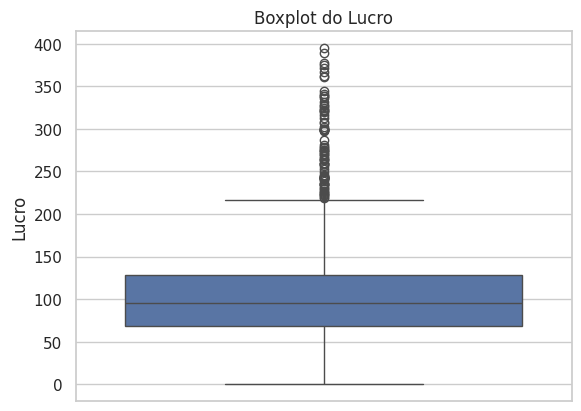

In [567]:
srn.boxplot(df['Lucro']).set_title('Boxplot do Lucro')

Com o outlier tratado este bloxplot consegue nos mostrar visualmente como os dados estão distribuidos. Tem uma boa concentração acima de 200 que representam as melhores vendas.

In [554]:
# Recalculando a coluna Lucro com base no Faturamento e na Margem de Lucro

df['Lucro'] = df['Faturamento'] * (df['Margem de Lucro'])
df.head(15)

,Data da Venda,Setor,Produto,Vendedor,Região,Estado,Cliente,Faturamento,Margem de Lucro,Lucro
0,01/01/2035,Carnes,Suína,Amaral,Sudeste,Minas Gerais,Atacado,633.45,0.13,82.3485
1,01/01/2035,Latícinio,Queijo,Leo,Sudeste,Minas Gerais,Atacarejo,611.40,0.07,42.7980
2,01/01/2035,Congelados,Sorvete,Leo,Nordeste,Rio Grande do Norte,Atacarejo,721.52,0.08,57.7216
3,01/01/2035,Carnes,Bovina,Daniele,Sudeste,São Paulo,Atacado,679.39,0.09,61.1451
4,01/01/2035,Carnes,Frango,Vanessa,Sul,Rio Grande do Sul,Varejo,964.52,0.19,183.2588
5,01/01/2035,Latícinio,Coalhada,Leo,Nordeste,Rio Grande do Norte,Atacarejo,565.70,0.08,45.2560
6,01/01/2035,Carnes,Frango,Vanessa,Nordeste,Rio Grande do Norte,Atacarejo,721.01,0.05,36.0505
7,01/01/2035,Carnes,Bovina,Vanessa,Sul,Rio Grande do Sul,Atacado,649.40,0.11,71.4340
8,02/01/2035,Latícinio,Coalhada,Vanessa,Sudeste,Minas Gerais,Atacarejo,789.01,0.19,149.9119
9,02/01/2035,Latícinio,Queijo,Daniele,Nordeste,Bahia,Atacado,574.30,0.05,28.7150


#### Salvando o DataFrame tratado

In [ ]:
#!pip install openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]1/2 [openpyxl]


In [570]:
df.to_excel('Campe_Supply_Tratado.xlsx', index=False)

## Iniciando a Análise do Dados

/tmp/ipykernel_1725/3831225528.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=faturamento_setor, x='Setor', y='Faturamento', palette='Blues_d')


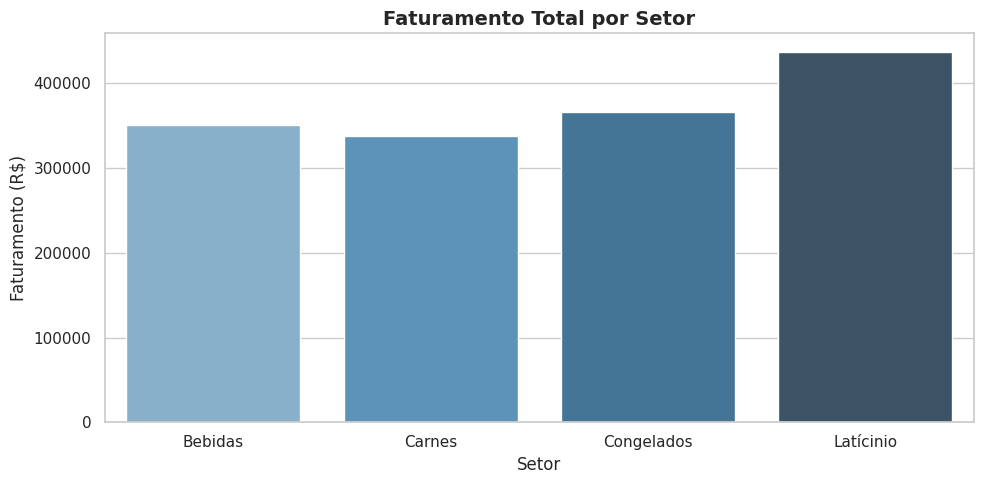

In [556]:
# Faturamento Total por Setor

# Configurando o estilo visual
sns.set_theme(style="whitegrid")

# Agrupando os dados por Setor e somando o Faturamento
faturamento_setor = df.groupby('Setor')['Faturamento'].sum().reset_index()

# Gerando o gráfico de barras
plt.figure(figsize=(10, 5))
sns.barplot(data=faturamento_setor, x='Setor', y='Faturamento', palette='Blues_d')
plt.title('Faturamento Total por Setor', fontsize=14, fontweight='bold')
plt.xlabel('Setor', fontsize=12)
plt.ylabel('Faturamento (R$)', fontsize=12)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Como são poucas opções, as colunas em pé são ótimas para bater o olho rápido e ver qual setor mais vendeu e o que menos vendeu.

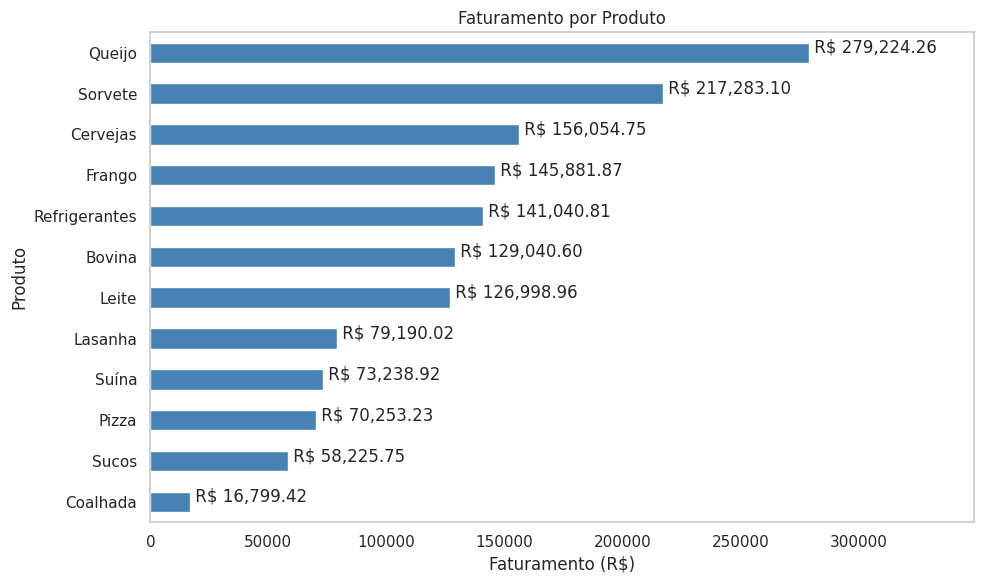

In [557]:
# Faturamento por Produto

# Agrupando e ordenando os dados
faturamento_produto = df.groupby('Produto')['Faturamento'].sum().sort_values()

# Criando o gráfico
faturamento_produto.plot(
    kind='barh', 
    figsize=(10, 6), 
    title='Faturamento por Produto',
    color='steelblue'
)

# Colocando os valores de faturamento ao lado das barras
for i, valor in enumerate(faturamento_produto):
    plt.text(valor, i, f" R$ {valor:,.2f}")

# Removendo grides do gráfico
plt.grid(False)

# Aumentando um pouco o eixo X para o texto caber na tela sem cortar
plt.xlim(0, faturamento_produto.max() * 1.25)

plt.xlabel('Faturamento (R$)')
plt.ylabel('Produto')
plt.tight_layout()

plt.show()

Como essas listas são compridas, deitar as barras facilita a leitura das informações seguindo o princípio que as pessoas tendem a ler do canto superior esquerdo para a direita e depois descendo.

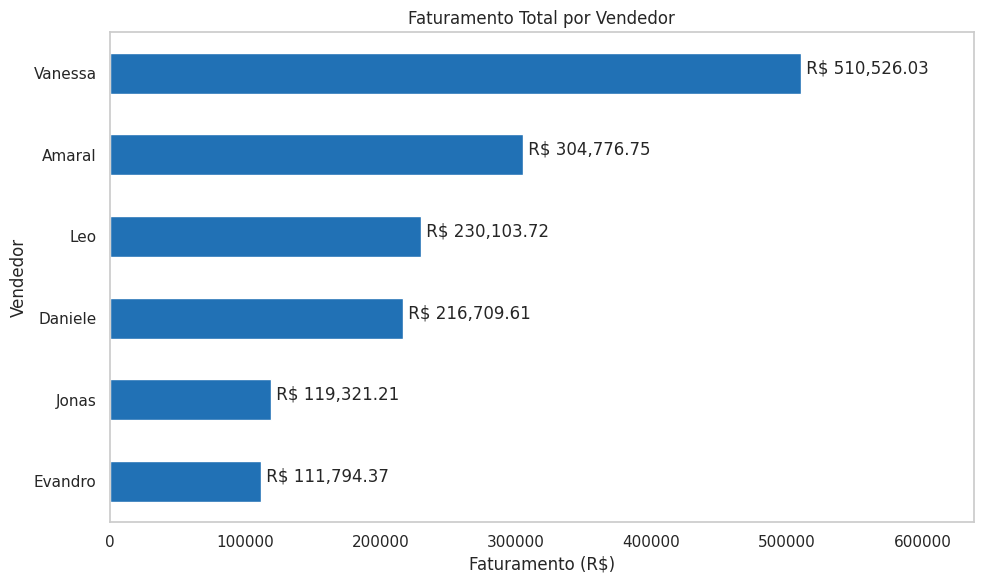

In [ ]:
# Faturamento Total por Vendedor

# Agrupando por Vendedor e ordenando
faturamento_vendedor = df.groupby('Vendedor')['Faturamento'].sum().sort_values()

# Criando o gráfico
faturamento_vendedor.plot(
    kind='barh', 
    figsize=(10, 6), 
    title='Faturamento Total por Vendedor',
    color='#2171b5'
)

# Colocando os valores exatos na frente das barras
for i, valor in enumerate(faturamento_vendedor):
    plt.text(valor, i, f" R$ {valor:,.2f}")

# Limpando o fundo e ajustando o espaço
plt.grid(False)
plt.xlim(0, faturamento_vendedor.max() * 1.25)
plt.ylabel('Vendedor')
plt.xlabel('Faturamento (R$)')
plt.tight_layout()

plt.show()

Como essas listas são compridas, deitar as barras facilita a leitura das informações seguindo o princípio que as pessoas tendem a ler do canto superior esquerdo para a direita e depois descendo.

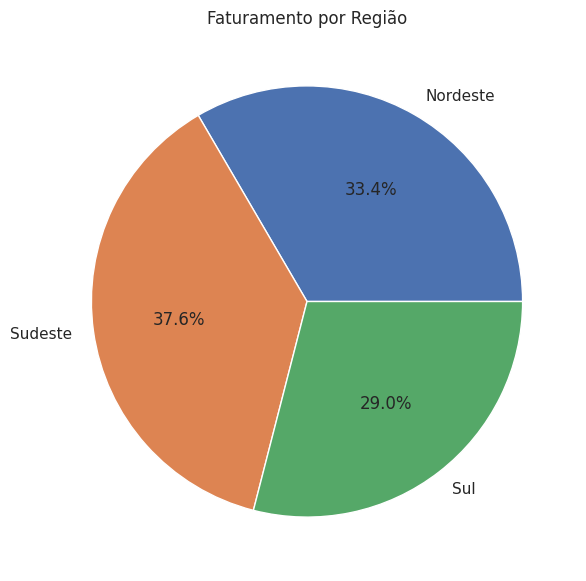

In [ ]:
# Faturamento por Região

# Agrupando os dados
faturamento_regiao = df.groupby('Região')['Faturamento'].sum()

# Plotando o gráfico
faturamento_regiao.plot(
    kind='pie',
    autopct='%1.1f%%', 
    figsize=(7, 7),
    title='Faturamento por Região'
)

# Escondendo a palavra "Faturamento" espremida no eixo Y
plt.ylabel('') 

plt.show()

A gráfico pizza funciona bem aqui porque só temos três regiões, mesmo não sendo um gráfico recomendável nesse caso por termos de fato só 3 variáveis não acaba sendo prejudicial.

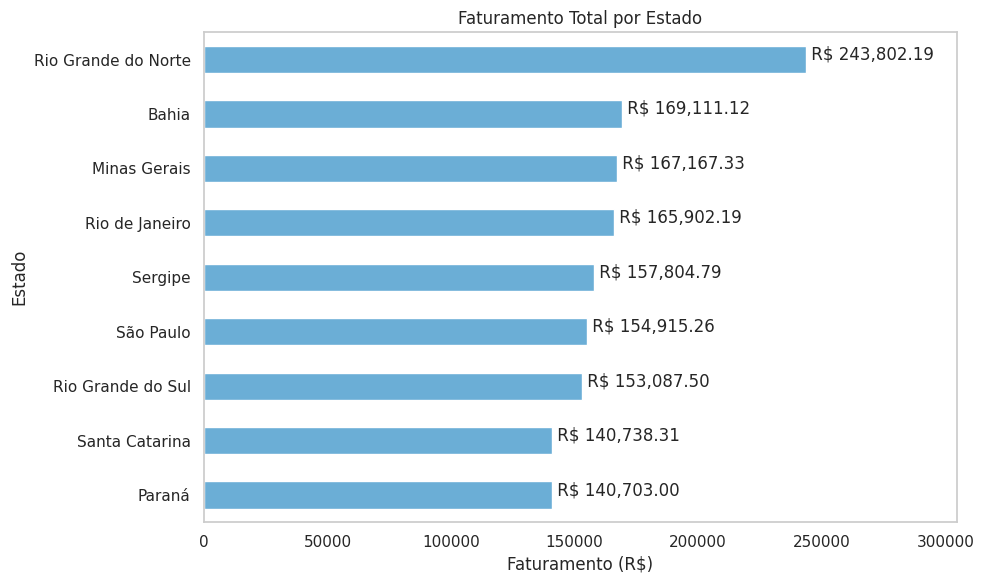

In [563]:
# Faturamento Total por Estado

# Agrupando por Estado e ordenando
faturamento_estado = df.groupby('Estado')['Faturamento'].sum().sort_values()

# Criando o gráfico
faturamento_estado.plot(
    kind='barh', 
    figsize=(10, 6), 
    title='Faturamento Total por Estado',
    color='#6baed6'
)

# Colocando os valores exatos na frente das barras
for i, valor in enumerate(faturamento_estado):
    plt.text(valor, i, f" R$ {valor:,.2f}")

# Limpando as linhas de grade do fundo e ajustando as margens
plt.grid(False)
plt.xlim(0, faturamento_estado.max() * 1.25)
plt.ylabel('Estado')
plt.xlabel('Faturamento (R$)')
plt.tight_layout()

plt.show()

Como essas listas são compridas, deitar as barras facilita a leitura das informações seguindo o princípio que as pessoas tendem a ler do canto superior esquerdo para a direita e depois descendo.

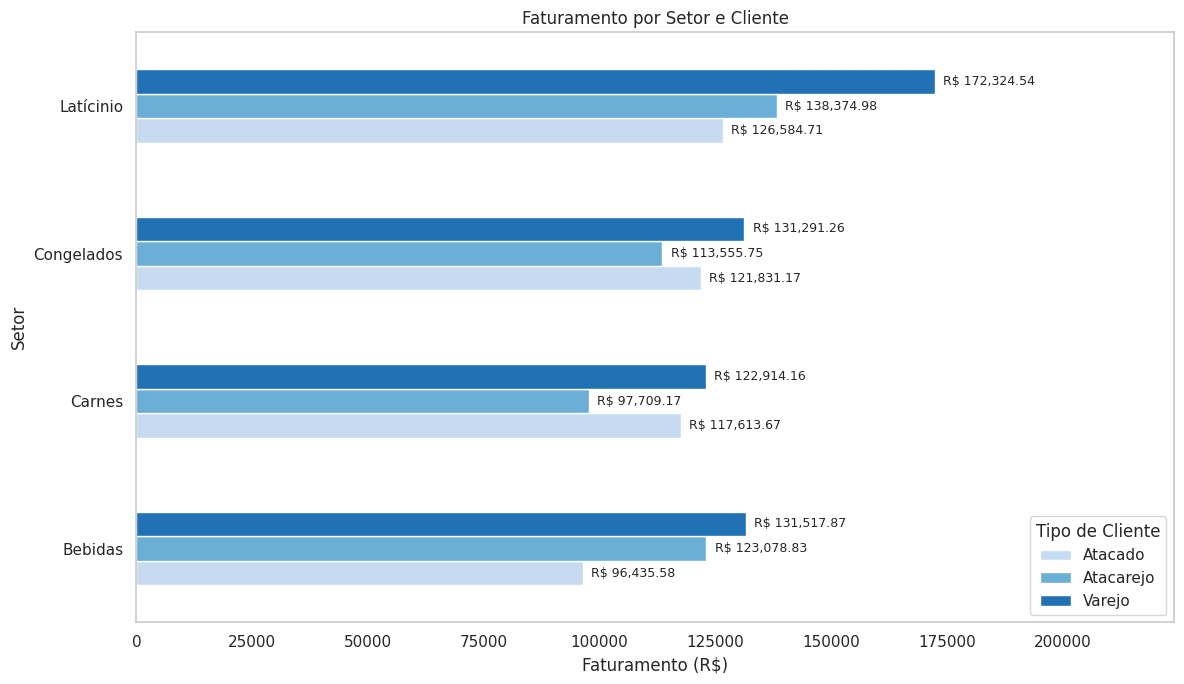

In [561]:
# Faturamento por Setor e Tipo de Cliente

# Agrupando por Setor e Cliente
faturamento_setor_cliente = df.groupby(['Setor', 'Cliente'])['Faturamento'].sum().unstack()

# Criando o gráfico e guardando na variável 'ax'
ax = faturamento_setor_cliente.plot(
    kind='barh', 
    figsize=(12, 7),
    title='Faturamento por Setor e Cliente',
    color=['#c6dbef', '#6baed6', '#2171b5'] 
)

# Varrendo os grupos de barras 
for container in ax.containers:
    # Criando o texto formatado em Reais para cada barra
    labels = [f" R$ {valor:,.2f}" for valor in container.datavalues]
    # Cola o texto na frente da barra
    ax.bar_label(container, labels=labels, padding=3, fontsize=9)

# Limpando o visual e ajustando os detalhes
plt.grid(False) # Tira as linhas de fundo
plt.ylabel('Setor')
plt.xlabel('Faturamento (R$)')

# Aumentando o limite do eixo X em 30% para os textos não baterem na borda da imagem
plt.xlim(0, faturamento_setor_cliente.max().max() * 1.3)

plt.legend(title='Tipo de Cliente')
plt.tight_layout()

plt.show()

Aqui juntei as barras lado a lado para responder duas perguntas de uma vez: qual setor traz mais dinheiro e, dentro dele, se quem compra mais é o Atacado, o Varejo ou o Atacarejo.

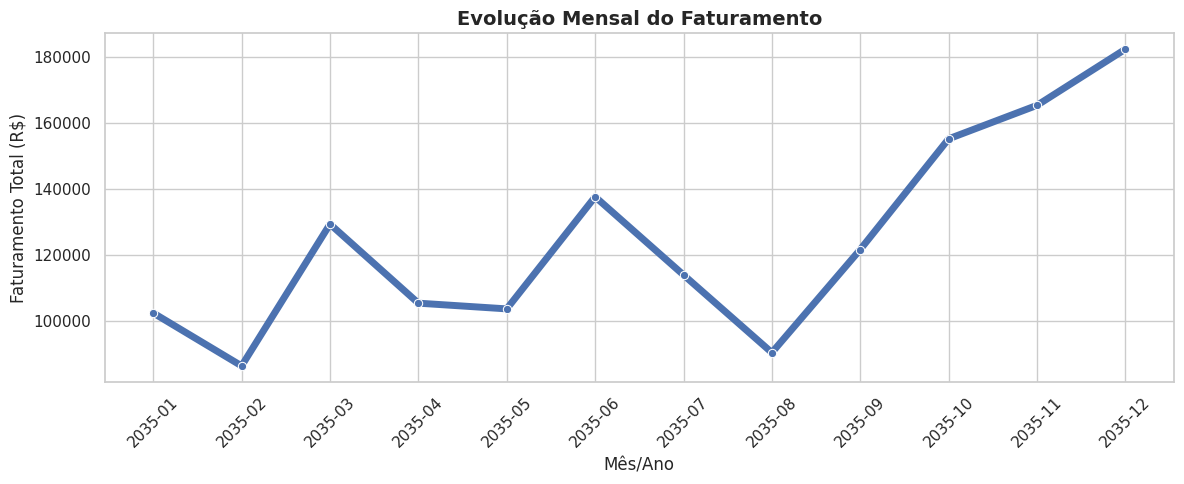

In [559]:
# Evolução Mensal do Faturamento

# Convertendo para o período mensal para facilitar
df_temp = df.dropna(subset=['Data da Venda']).copy()
df_temp['Mes_Ano'] = pd.to_datetime(df_temp['Data da Venda'], format='%d/%m/%Y').dt.to_period('M').astype(str)
faturamento_tempo = df_temp.groupby('Mes_Ano')['Faturamento'].sum().reset_index()

# Gerando o gráfico
plt.figure(figsize=(12, 5))
sns.lineplot(data=faturamento_tempo, x='Mes_Ano', y='Faturamento', marker='o', color='b', linewidth=25/5)
plt.title('Evolução Mensal do Faturamento', fontsize=14, fontweight='bold')
plt.xlabel('Mês/Ano', fontsize=12)
plt.ylabel('Faturamento Total (R$)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Melhor gráfico para representar dados correntes numa linha do tempo, a linha sobe e desce mostrando certinho os meses em que foi mal e a recuperação até o fim do ano.

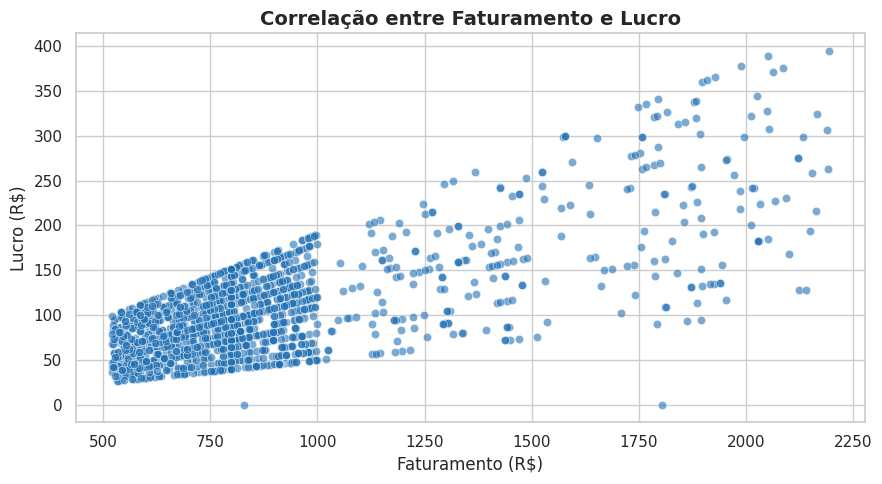

In [566]:
# Gráfico de dispersão - Correlação entre Faturamento e Lucro

plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x='Faturamento', y='Lucro', alpha=0.6, color='#2171b5')
plt.title('Correlação entre Faturamento e Lucro', fontsize=14, fontweight='bold')
plt.xlabel('Faturamento (R$)', fontsize=12)
plt.ylabel('Lucro (R$)', fontsize=12)
plt.tight_layout()
plt.show()

Serve para tirar a prova real. A gente olha para os pontinhos subindo juntos e confirma que vender mais está realmente colocando mais lucro no nosso bolso.

## Conclusão

#### Descrição do Aprendizado
A atividade foi ótima para fixar todo o conteúdo, desde a parte exploratória dos dados até a análise deles, passando pelo tratamento. Entender melhor qual gráfico usar para representar um determinado insight foi muito importante para o desenvolvimento, todos esses conceitos fizeram ainda mais sentido para mim. Como ponto de melhoria, acho que eu poderia ter realizado o tratamento dos dados de uma forma mais direta — no caso, explorando uma coluna e já a tratando —, mas não sei se, de fato, essa seria a melhor opção.

#### Análise Exploratória
Para realizar a análise exploratória, parti do princípio de analisar separadamente cada coluna, achar seus problemas e tratar tudo posteriormente na etapa de tratamento dos dados. Primeiramente, percebi que precisava alterar os nomes das colunas e também que haveria colunas que deveriam ser excluídas. De uma forma geral, identifiquei que todas as colunas apresentavam valores nulos que deveriam ser tratados depois. 

Nas colunas categóricas, identifiquei que havia muitos registros com erro de digitação. Já nas colunas numéricas, identifiquei que elas não estavam no seu tipo numérico correto e que, além de possuírem valores nulos, também apresentaram outliers (como foi o caso de Faturamento e Lucro).

#### Tratamento dos Dados
Para tratar os dados, como citado na análise exploratória, primeiramente alterei os nomes das colunas e depois excluí aquelas que não agregavam valor à análise. Logo após, parti para o tratamento individual de cada coluna, começando pela `Data da Venda`, onde padronizei para o formato de data do Brasil. Para tratar os valores nulos, utilizei a técnica de preencher com o valor anterior e o posterior, caso o primeiro fosse nulo.

Para as colunas categóricas (`Setor`, `Produto`, `Vendedor`, `Região`, `Estado` e `Cliente`), precisei tratar primeiramente os erros de digitação. Para isso, utilizei a biblioteca `difflib` com a função `get_close_matches` para corrigir as inconsistências de forma automatizada, sem precisar mapear cada termo manualmente. Os valores nulos para todas elas eu substituí inserindo o valor da moda.

Para as colunas numéricas, tratei os valores nulos inserindo a mediana, justamente por ela não ser impactada pelos outliers. Para corrigir os outliers, tive que tomar abordagens diferentes para cada caso: para o `Faturamento`, acabei excluindo o registro isolado com valor de R$ 8.581,60; e, no caso do `Lucro`, excluí todos os registros maiores que 1.000.000 para remover a anomalia.

#### Escolha dos Gráficos
Sobre as escolhas dos gráficos, os motivos já foram citados logo após cada plotagem, mas resumo aqui a linha de raciocínio utilizada:

* **Setor (Barras Verticais):** Como são poucas opções, as colunas em pé são ótimas para bater o olho rápido e ver quem é o líder de vendas.
* **Produtos, Vendedores e Estados (Barras Horizontais):** Como essas listas são mais longas, deitar as barras facilita muito a leitura dos nomes, garantindo que a audiência consiga ler confortavelmente.
* **Região (Gráfico de Pizza):** Funciona super bem aqui porque temos apenas três categorias.
* **Setor x Cliente (Barras Agrupadas):** Juntar as barras lado a lado responde a duas perguntas de uma só vez: qual setor traz mais dinheiro e, dentro dele, qual é o comportamento do Atacado, Varejo e Atacarejo.
* **Evolução Mensal (Gráfico de Linha):** É o melhor jeito de contar a história e a tendência das vendas ao longo do tempo, mostrando perfeitamente as altas e baixas dos meses.
* **Faturamento x Lucro (Dispersão):** Serve para tirar a prova real do modelo, confirmando visualmente que vender mais está, de fato, gerando mais lucro de forma proporcional.

